<a href="https://colab.research.google.com/github/gabimazzo-coder/Pre-entrega-10/blob/main/Pre_entrega_10_pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTACION DE LIBRERIAS

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

IMPORTACIÓN DE DATASET

In [6]:
import pandas as pd

# Importar un archivo CSV (reemplaza 'archivo.csv' por tu ruta o nombre)
df = pd.read_csv('patient_churn_dataset01.csv')

# Mostrar las primeras 5 filas para verificar los datos
print(df.head())

  PatientID  Age  Gender State  Tenure_Months          Specialty  \
0    C20000   41  Female    PA             62         Pediatrics   
1    C20001   43  Female    GA             44  Internal Medicine   
2    C20002   21    Male    MI            120  Internal Medicine   
3    C20003   65    Male    FL            118   General Practice   
4    C20004   18  Female    CA             70         Cardiology   

  Insurance_Type  Visits_Last_Year  Missed_Appointments  \
0       Medicaid                 1                    0   
1       Self-Pay                 7                    4   
2       Medicaid                15                    5   
3        Private                10                    3   
4       Medicaid                 5                    4   

   Days_Since_Last_Visit  ... Overall_Satisfaction  Wait_Time_Satisfaction  \
0                    564  ...                  3.5                     4.9   
1                    254  ...                  2.6                     3.1   
2 

Celda 2: División del conjunto de datos (80/20)

In [9]:
# Separar características (X) y variable objetivo (y)
X = df.drop(columns=['Churned'])
y = df['Churned']

# División 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Registros de entrenamiento: {X_train.shape[0]} | Registros de prueba: {X_test.shape[0]}")

Registros de entrenamiento: 1600 | Registros de prueba: 400


Celda 3: Entrenamiento del modelo (Random Forest)

In [12]:
# 1. Eliminar identificadores irrelevantes y aplicar codificación One-Hot a las columnas de texto
X_encoded = pd.get_dummies(X.drop(columns=['PatientID']), drop_first=True)

# 2. Volver a dividir los datos procesados
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.20, random_state=42, stratify=y)

# 3. Instanciar y entrenar el modelo Random Forest con los datos numéricos
modelo = RandomForestClassifier(random_state=42, n_estimators=100)
modelo.fit(X_train, y_train)

# 4. Predicciones
y_pred = modelo.predict(X_test)
print("Modelo entrenado exitosamente con datos codificados.")

Modelo entrenado exitosamente con datos codificados.



Celda 4: Evaluación de Métricas



--- METRICAS DE EVALUACIÓN ---
Accuracy:  0.6850
Precision: 0.6889
Recall:    0.9817
F1-Score:  0.8097



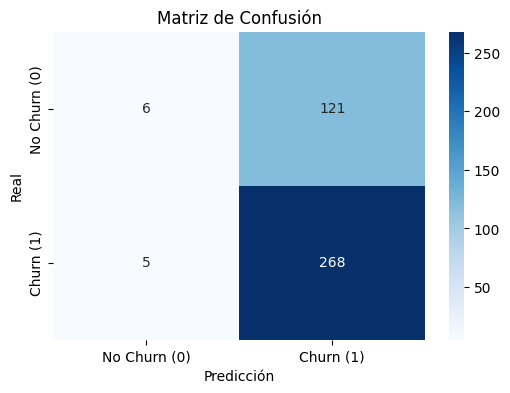

In [13]:
# Cálculo de métricas individuales
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("--- METRICAS DE EVALUACIÓN ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

# Graficar Matriz de Confusión de forma visual
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn (0)', 'Churn (1)'],
            yticklabels=['No Churn (0)', 'Churn (1)'])
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()


Celda 5 (Markdown): Interpretación del problema de Churn

### Justificación de la Métrica Crítica: Recall

En un problema de **Churn (pérdida de clientes)**, la métrica más importante suele ser el **Recall (Sensibilidad)**.

**¿Por qué?**
El Recall mide la cantidad de clientes que realmente iban a abandonar la empresa y que el modelo logró identificar correctamente. En este contexto, un **Falso Negativo (FN)** representa a un cliente que *sí se va a ir*, pero el modelo clasifica erróneamente como "estable/seguro".

**Impacto de los Costos:**
*   **Costo de un Falso Negativo (Alto):** Si el modelo no detecta a este cliente, la empresa no tomará ninguna acción de retención. El cliente se marchará, lo que implica perder el valor de vida del cliente (CLV) y asumir el alto costo financiero de adquirir un cliente nuevo para reemplazarlo.
*   **Costo de un Falso Positivo (Bajo):** Si el modelo cree que un cliente se va a ir pero en realidad planeaba quedarse, la empresa podría ofrecerle un incentivo o descuento de retención. Aunque esto genera un pequeño gasto innecesario, es drásticamente menor que perder al cliente por completo.

Por lo tanto, se prefiere maximizar el **Recall** para capturar la mayor cantidad de abandonos posibles, tolerando algunos falsos positivos en el proceso.
